# **Activity 04 - Bills Counting (HSV)**

Load the photo, resize it, blur it, and convert to HSV.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image
image = cv2.imread('PaperBills.jpg')
if image is None:
    raise FileNotFoundError("Image not found.")

# Resize to a fixed width but keep the aspect ratio so the bills are not distorted
TARGET_W = 800
h0, w0 = image.shape[:2]
image = cv2.resize(image, (TARGET_W, int(h0 * TARGET_W / w0)), interpolation=cv2.INTER_AREA)

# Convert to RGB (for display)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Light blur smooths print texture and glare so the HSV masks come out cleaner
blurred = cv2.GaussianBlur(image, (5, 5), 0)
hsv = cv2.cvtColor(blurred, cv2.COLOR_BGR2HSV)  # HSV (for color detection)

Define the HSV range of each denomination and preview its raw mask.

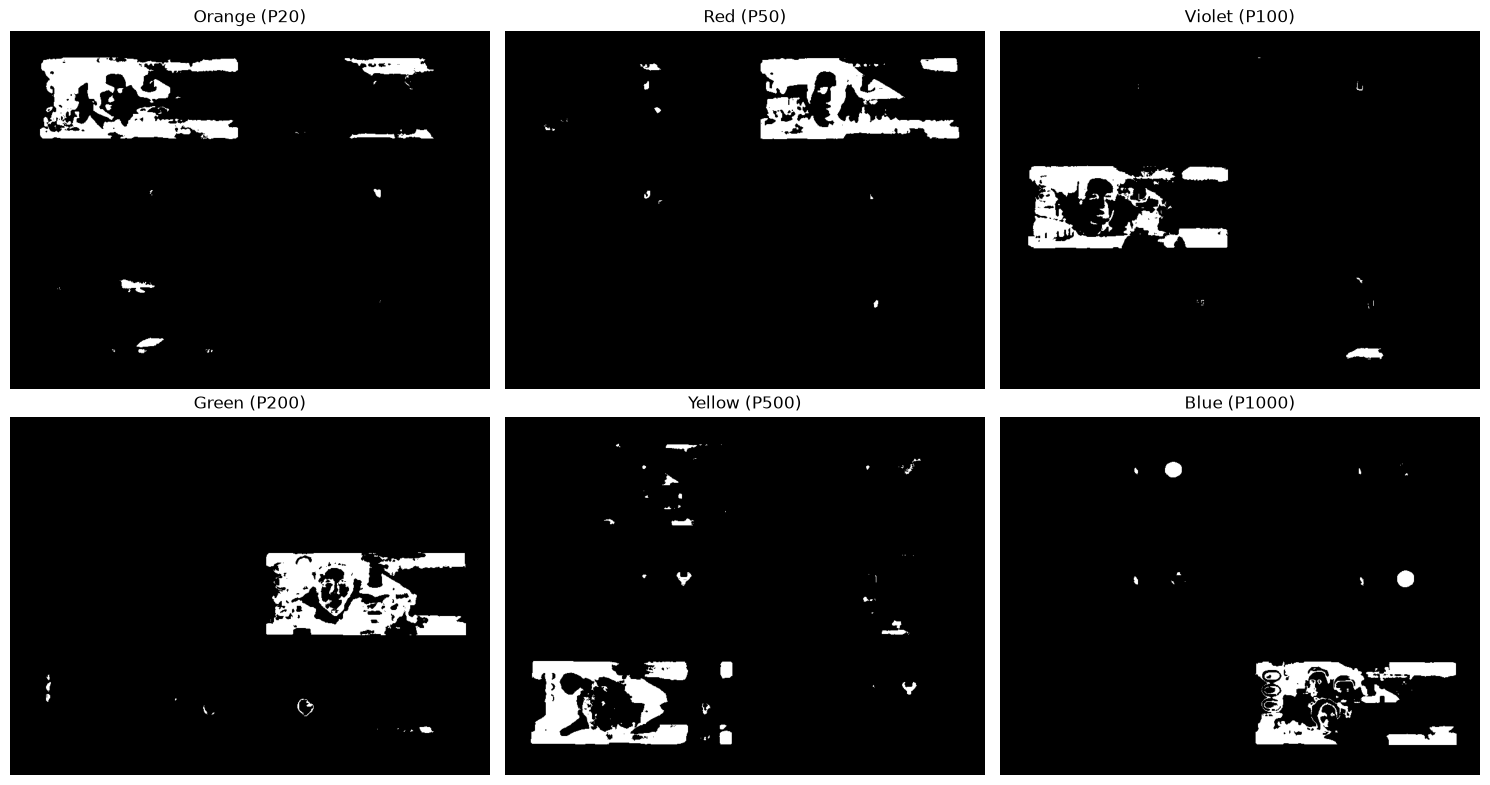

In [3]:
# OpenCV HSV scale: H 0-179, S 0-255, V 0-255
# Minimum V is kept high so the dark background is never picked up.
bill_colors = {
    'Orange':   {'ranges': [((6,   70, 100), (16,  255, 255))],
                    'box_color': (255, 140, 0),   'value': 20},
    # Red wraps around the hue circle, so it needs two ranges (near 0 and near 180)
    'Red':      {'ranges': [((0,   70, 100), (4,   255, 255)),
                            ((170, 70, 100), (180, 255, 255))],
                    'box_color': (255, 0, 0),     'value': 50},
    'Violet':   {'ranges': [((135, 25, 70),  (162, 255, 235))],
                    'box_color': (148, 0, 211),   'value': 100},
    'Green':    {'ranges': [((34,  30, 70),  (62,  255, 255))],
                    'box_color': (0, 150, 0),     'value': 200},
    'Yellow':   {'ranges': [((18,  60, 90),  (28,  255, 255))],
                    'box_color': (255, 215, 0),   'value': 500},
    'Blue':     {'ranges': [((95,  40, 110), (112, 255, 255))],
                    'box_color': (0, 0, 255),     'value': 1000},
}

def build_mask(hsv_img, ranges):
    """Combine one or more HSV ranges (red wraps around 0/180) into a single mask."""
    mask = np.zeros(hsv_img.shape[:2], dtype=np.uint8)
    for lower, upper in ranges:
        m = cv2.inRange(hsv_img, np.array(lower), np.array(upper))
        mask = cv2.bitwise_or(mask, m)
    return mask

# Preview the raw partial-color mask for every denomination
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, (label, info) in zip(axs.flatten(), bill_colors.items()):
    mask = build_mask(hsv, info['ranges'])
    ax.imshow(mask, cmap='gray')
    ax.set_title(f"{label} (P{info['value']})")
    ax.axis("off")
plt.tight_layout()
plt.show()

Clean each mask and find one bounding box per bill.

In [4]:
h, w = image.shape[:2]

# Scale the morphology kernel and the minimum blob size to the image resolution
k_size = max(15, int(min(h, w) * 0.06))
if k_size % 2 == 0:
    k_size += 1
close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))
noise_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
min_area = int(h * w * 0.015)  # ignore blobs smaller than ~1.5% of the image

detections = []  # (label, value, (x, y, box_w, box_h))
clean_masks = {}  # kept for the visualization below

for label, info in bill_colors.items():
    mask = build_mask(hsv, info['ranges'])
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, noise_kernel)                 # remove speckle noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, close_kernel, iterations=2)  # bridge gaps (portrait, watermark, text)
    clean_masks[label] = mask

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in contours:
        if cv2.contourArea(c) < min_area:
            continue  # small stray blobs of the same hue (seals, holograms) are not bills
        x, y, box_w, box_h = cv2.boundingRect(c)
        detections.append((label, info['value'], (x, y, box_w, box_h)))

# Order detections top-to-bottom, then left-to-right (matches the photo layout)
row_h = h // 3
detections.sort(key=lambda d: (d[2][1] // row_h, d[2][0]))

print(f"Detected {len(detections)} bill(s).")

Detected 6 bill(s).


Draw the labeled boxes and print the count and total value.

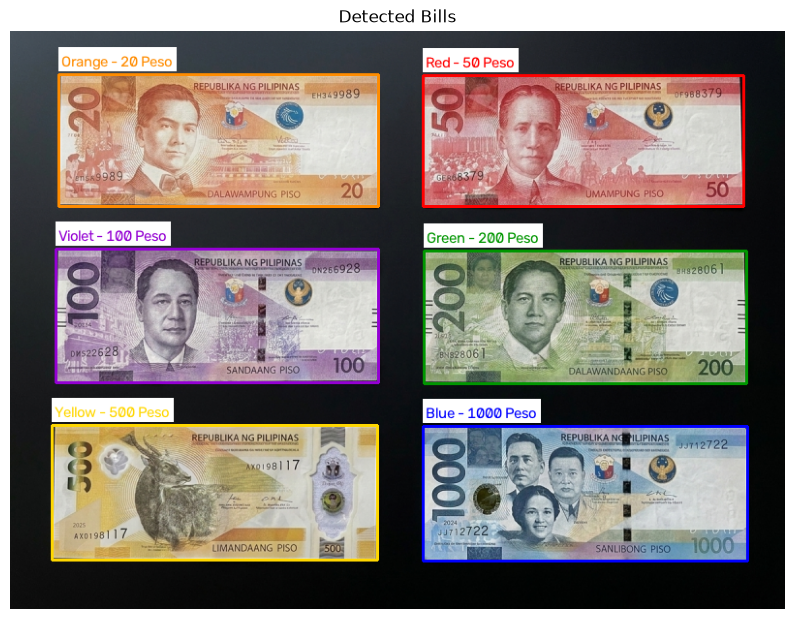

Detected bills:
  Orange: 20 Peso
  Red: 50 Peso
  Violet: 100 Peso
  Green: 200 Peso
  Yellow: 500 Peso
  Blue: 1000 Peso

Total count: 6
Total value: P1870

Count per denomination:
  P  20 (Orange): 1
  P  50 (Red): 1
  P 100 (Violet): 1
  P 200 (Green): 1
  P 500 (Yellow): 1
  P1000 (Blue): 1


In [5]:
# Draw a labeled box on every detected bill
output_img = image_rgb.copy()

for label, value, (x, y, box_w, box_h) in detections:
    color = bill_colors[label]['box_color']
    cv2.rectangle(output_img, (x, y), (x + box_w, y + box_h), color, 2)

    text = f"{label} - {value} Peso"
    (text_w, text_h), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    text_y = max(y - 8, text_h + 4)  # keep the label inside the image for boxes at the top edge
    cv2.rectangle(output_img, (x, text_y - text_h - 6), (x + text_w + 6, text_y + 4), (255, 255, 255), -1)
    cv2.putText(output_img, text, (x + 3, text_y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

plt.figure(figsize=(10, 8))
plt.imshow(output_img)
plt.title("Detected Bills")
plt.axis("off")
plt.show()

# Summary + total peso value
print("Detected bills:")
total_value = 0
for label, value, box in detections:
    print(f"  {label}: {value} Peso")
    total_value += value

print(f"\nTotal count: {len(detections)}")
print(f"Total value: P{total_value}")

# Count per denomination
print("\nCount per denomination:")
for label, info in bill_colors.items():
    n = sum(1 for d in detections if d[0] == label)
    print(f"  P{info['value']:>4} ({label}): {n}")